# `Материалы кафедры ММП факультета ВМК МГУ. Введение в глубокое обучение.`

## `Задание 01. Полносвязная нейронная сеть на numpy`.

#### Фамилия, имя: 

Дата выдачи: <span style="color:red">__13 февраля__</span>.

Мягкий дедлайн: <span style="color:red">__27 февраля 03:00__</span>.

Стоимость: __10 баллов__ (основная часть заданий) + __3 балла__ (дополнительные задания).

<span style="color:red">__В ноутбуке все клетки должны выполняться без ошибок при последовательном их выполнении.__</span>

#### `Москва, 2026`

In [3]:
import numpy as np

## `Теоретическая часть (3 балла)`

В этом блоке вам нужно решить 3 задания.

### `Задание 1. Градиенты для слоя Batch normalization (1.5 балла)`

Рассмотрим слой Batch normalization. Пусть на вход этого слоя был подан батч из $n$ объектов, при этом у всех объектов по 1 признаку. Представим вход BN слоя в виде $X \in \mathbb{R}^{n \times 1}$.

Тогда в этом слое производятся следующие вычисления:

$$ \mu = \frac1n \sum_{i=1}^{n} X_i $$

$$ \sigma^2 = \frac1n \sum_{i=1}^{n} \left( X_i - \mu \right) ^2 $$

$$ \tilde{y_i} = \frac{X_i - \mu}{\sqrt{\sigma^2 + \varepsilon}} $$

$$ y_i = \gamma \tilde{y_i} + \delta $$

Выходом BN слоя является $y_i$, а $\gamma,\delta\in\mathbb{R}$ — параметры, которые подбираются во время обучения вместе с другими параметрами нейронной сети (наряду, например, с весами линейного слоя).

Рассмотрим нейронную сеть, в которой есть BN слой. Предположим, что вычисления в нейронной сети завершаются подсчетом функции потерь $\mathcal{L}$. Пусть мы выполнили прямой проход по нейронной сети и сейчас делаем обратный проход с помощью метода обратного распространения ошибки. Пусть BN слою пришел градиент функции потерь по выходу BN слоя ($\nabla_{y} \mathcal{L}$).

В этом задании вам нужно записать вычисление градиента функции потерь по параметрам слоя BN $\gamma$ и $\delta$ ($\nabla_{\gamma} \mathcal{L}$, $\nabla_{\delta} \mathcal{L}$) через $\nabla_{y} \mathcal{L}$, а также вам нужно записать вычисление градиента функции потерь по входу слоя BN $X$ ($\nabla_{X} \mathcal{L}$) через $\nabla_{y} \mathcal{L}$.

Хочу заметить, в данном задании мы рассматриваем объекты всего с 1 признаком, чтобы упростить выкладки.

__Ваше решение:__

1. $\frac{\partial L}{\partial \gamma} = \sum_{i=1}^{n} \frac{\partial L}{\partial y_i} \cdot \frac{\partial y_i}{\partial \gamma}  = \sum_{i=1}^{n} \frac{\partial L}{\partial y_i} \cdot \hat{y}_i \Rightarrow \nabla_{\gamma} \mathcal{L} = (\nabla_{y} \mathcal{L} \cdot \hat{y})$


2. $\frac{\partial L}{\partial \delta} = \sum_{i=1}^{n} \frac{\partial L}{\partial y_i} \cdot \frac{\partial y_i}{\partial \delta}  = \sum_{i=1}^{n} \frac{\partial L}{\partial y_i} \Rightarrow \nabla_{\delta} \mathcal{L} = \nabla_{y} \mathcal{L}$

3. $\frac{\partial L}{\partial X} = ?$

Разберем по частям: $\frac{\partial L}{\partial X_i} = \sum_{j=1}^{n} \frac{\partial L}{\partial \hat{y}_j} \cdot \frac{\partial \hat{y}_j}{\partial X_i} = \sum_{j=1}^{n} \frac{\partial L}{\partial y_j} \cdot \frac{\partial y_j}{\partial \hat{y}_j} \cdot \frac{\partial \hat{y}_j}{\partial X_i} = \sum_{j=1}^{n} \frac{\partial L}{\partial y_j} \cdot \gamma \cdot \frac{\partial \hat{y}_j}{\partial X_i} $

Найдем: $\frac{\partial \hat{y}_j}{\partial X_i}$

a) *i = j*: 

$\frac{\partial \hat{y}_j}{\partial X_i} = \frac{1}{\sigma^2 + \varepsilon} \cdot ((1 - \frac{\partial \mu}{\partial X_i}) \cdot \sqrt{\sigma^2 + \varepsilon} - \frac{X_i - \mu}{2\sqrt{\sigma^2 + \varepsilon}} \cdot \frac{\partial \sigma^2}{\partial X_i})$

$\frac{\partial \mu}{\partial X_i} = \frac{1}{n} \cdot \frac{\partial }{\partial X_i} \sum_{j=1}^{n} X_j = \frac{1}{n}$

$\frac{\partial \sigma^2}{\partial X_i} = \frac{1}{n} \cdot \frac{\partial }{\partial X_i} \sum_{j=1}^{n} \left( X_j - \mu \right) ^2 = \frac{1}{n} \sum_{j=1}^{n} 2 \left( X_j - \mu \right)(\frac{\partial X_j}{\partial X_i} - \frac{\partial \mu}{\partial X_i}) = \frac{2}{n} \left[ \sum_{j=1}^{n} (X_j - \mu) \frac{\partial X_j}{\partial X_i} - \sum_{j=1}^{n} (X_j - \mu) \cdot \frac{1}{n} \right] = \frac{2}{n} \cdot (X_i - \mu)$, т.к. сумма отклонений от среднего равна нулю и второе слагаемое зануляется.

b) *i $\neq$ j*:

$\frac{\partial \hat{y}_j}{\partial X_i} = \frac{1}{\sigma^2 + \varepsilon} \cdot ((- \frac{\partial \mu}{\partial X_i}) \cdot \sqrt{\sigma^2 + \varepsilon} - \frac{X_i - \mu}{2\sqrt{\sigma^2 + \varepsilon}} \cdot \frac{\partial \sigma^2}{\partial X_i})$

Аналогично пункту *а)*:

$\frac{\partial \mu}{\partial X_i}  = \frac{1}{n}$

$\frac{\partial \sigma^2}{\partial X_i} = \frac{2}{n} \cdot (X_i - \mu)$

Тогда в итоге получим: 

$\frac{\partial L}{\partial X_i} = \frac{1}{\sqrt{\sigma^2 + \varepsilon}} \cdot \left( \frac{\partial L}{\partial \hat{y}_i} - \frac{1}{n} \sum_{j=1}^{n} \frac{\partial L}{\partial \hat{y}_j} - \frac{1}{n} \hat{y}_i \sum_{j=1}^{n} \frac{\partial L}{\partial \hat{y}_j} \hat{y}_j \right)$

### `Задание 2. Вывод инициализации весов линейного слоя при использовании ReLU в качестве функции активации (1 балл)`

Рассмотрим полносвязную нейронную сеть с функцией активации $g(y)$. Пусть сеть состоит из $L$ слоев и размер входа слоя $l$ равен $n_l\ \ (l = \overline{1, L})$.

Обозначим за $x^l \in \mathbb{R}^{n_{l}}$ вход слоя $l$, за $y^l \in \mathbb{R}^{n_{l+1}}$ — выход слоя $l$, за $W^l \in \mathbb{R}^{n_{l+1} \times n_{l}}$ — веса слоя $l$, за $b^l \in \mathbb{R}^{n_{l+1}}$ — вектор сдвига слоя $l$.

Тогда
$$y^l = W^l x^l + b^l,$$
$$x^{l+1} = g(y^l).$$

На паре вы выводили хорошую инициализацию для линейного слоя в случае, когда в качестве функции активации $g(y)$ в нейронной сети используется гиперболический тангенс $g(y) = \tanh(y)$. Сейчас вам нужно сделать подобный вывод для случая, когда в сети в качестве функций активации используется $g(y) = ReLU(y) = \max(0, y)$.

Сделаем следующие предположения насчет того, как распределены веса $W^l$, вектор сдвига $b^l$, входной вектор $x^l$, выходной вектор $y^l$ линейного слоя и градиенты функции потерь $\frac{\partial L}{\partial y^{l}}$ $(l = \overline{1, L}$):

1. Все компоненты в $W^l$ распределены одинаково и независимо друг от друга;
2. Все компоненты в $y^l$ распределены одинаково и независимо друг от друга;
3. Все компоненты в $x^l$ распределены одинаково и независимо друг от друга;
4. Все компоненты в $\frac{\partial L}{\partial y^{l}}$ распределены одинаково и независимо друг от друга;
5. Все компоненты в $W^l$ и все компоненты в $x^l$ независимы друг от друга;
6. Все компоненты в $W^l$ имеют четную плотность распределения (то есть симметричную относительно нуля: $p_{W^l}(-x) = p_{W^l}(x)$);
7. Все компоненты в $W^l$ имеют конечное матожидание;
8. Вектор $b^l$ инициализирован нулями.


Подсказки:
1. Из пунктов 6 и 7 следует, что все компоненты в $W^l$ имеют нулевое среднее ($\mathbb{E} W^l_{ij} = 0\ \ \forall i = \overline{1, n_{l+1}}, j = \overline{1, n_{l}}$) (докажите);
2. Из пунктов 6 и 7 следует, что все компоненты в $y^l$ имеют нулевое среднее и четную плотность распределения (докажите).

__Ваше решение:__

**Прямой проход:**
$$
y^l = W^l x^l,\quad x^{l+1} = \mathrm{ReLU}(y^l).
$$
Считаем элементы независимы с нулевым средним. Из симметрии распределения $y^l$ и ReLU:
$$
\mathbb{E}[(x^{l+1})^2] = \frac12 \mathbb{E}[(y^l)^2].
$$
Тогда дисперсия выхода линейного слоя:
$$
\mathrm{Var}[y^l] = n_l\,\mathrm{Var}[W^l]\,\mathrm{Var}[x^l].
$$
Подставляя $\mathrm{Var}[x^l] = \frac12 \mathrm{Var}[y^{l-1}]$ и требуя $\mathrm{Var}[y^l] = \mathrm{Var}[y^{l-1}]$, получаем
$$
\mathrm{Var}[W^l] = \frac{2}{n_l}.
$$

**Обратный проход:**
$$
\frac{\partial L}{\partial x^l} = (W^l)^T\frac{\partial L}{\partial y^l},\quad 
\frac{\partial L}{\partial y^{l-1}} = \frac{\partial L}{\partial x^l}\cdot\mathbf{1}_{x^l>0}.
$$
Аналогично получаем условие
$$
\mathrm{Var}[W^l] = \frac{2}{n_{l+1}}.
$$

### `Задание 3. Почему функция активации` $ReLU(y) = \max(0, y)$ `предпочтительней сигмоиды` $\sigma(y) = \frac{1}{1 + \exp(-y)}$ `в нейронных сетях? (0.5 балла)`

Дайте развернутый ответ на вопрос "Почему функция активации $ReLU(y) = \max(0, y)$ предпочтительней сигмоиды $\sigma(y) = \frac{1}{1 + \exp(-y)}$ в нейронных сетях?"

__Ваш ответ:__

Сигмоида не решает проблему затухания градиента при обратном проходе. Максимальное значение производной сигмоиды [$\sigma' = \sigma(1 - \sigma)$] = 0.25, значит, при каждом прохождении слоя с сигмоидой градиент уменьшается в четыре раза, что приводит к очень сильному затуханию. В отличие от сигмоиды, у функции ReLU нет такой проблемы: при x > 0 значение производной равно 1.

---

## `Практическая часть (7 баллов)`

### `Реализация нейронной сети (3 балла)`

В этом задании вы обучите полносвязную нейронную сеть распознавать рукописные цифры (а что же еще, если не их :), [почти] самостоятельно реализовав все составляющие алгоритма обучения и предсказания.

Для начала нам понадобится реализовать прямой и обратный проход через слои. Наши слои будут соответствовать следующему интерфейсу (на примере "тождественного" слоя):

In [4]:
class IdentityLayer:
    """
    A building block. Each layer is capable of performing two things:

    - Process input to get output:           
    output = layer.forward(input)

    - Propagate gradients through itself:    
    grad_input = layer.backward(input, grad_output)

    Some layers also have learnable parameters.

    Modified code from cs.hse DL course *
    """
    def __init__(self):
        """
        Here you can initialize layer parameters (if any) 
        and auxiliary stuff. You should enumerate all parameters
        in self.params
        """
        # An identity layer does nothing
        self.params = []
        pass

    def forward(self, input):
        """
        Takes input data of shape [batch, input_units], 
        returns output data [batch, output_units]
        """
        # An identity layer just returns whatever it gets as input.
        self.input = input
        return input

    def backward(self, grad_output): 
        """
        Performs a backpropagation step through the layer, 
        with respect to the given input.

        To compute loss gradients w.r.t input, 
        you need to apply chain rule (backprop):

        d `loss` / d `input` = (d `loss` / d `layer`) * (d `layer` / d `input`)

        Luckily, you already receive d `loss` / d `layer` in argument, 
        so you only need to multiply it by d `layer` / d `input`.

        NB: Sometimes d `layer` / d `input` can be a 3D or even 4D tensor.
        So it's better to write down the `loss` differential and extract
        d `layer` / d `input` from it so that only 2D tensors were present.

        The method returns:
        * gradient w.r.t input (will be passed to 
          previous layer's backward method)
        * flattened gradient w.r.t. parameters (with .ravel() 
          applied to each gradient). 
          If there are no params, return []
        """
        # The gradient of an identity layer is precisely grad_output
        input_dim = self.input.shape[1]

        d_layer_d_input = np.eye(input_dim)

        return np.dot(grad_output, d_layer_d_input), [] # chain rule

#### `Слой нелинейности ReLU`

Для начала реализуем слой нелинейности $ReLU(y) = \max(0, y)$. Параметров у слоя нет. Метод `forward` должен вернуть результат поэлементного применения $ReLU$ к входному массиву, метод `backward` — градиент функции потерь по входу слоя. В нуле будем считать производную равной 0. Обратите внимание, что при обратном проходе могут понадобиться величины, посчитанные во время прямого прохода, поэтому их стоит сохранить как атрибут класса.

In [5]:
class ReLU:
    """
    Modified code from cs.hse DL course *
    """
    def __init__(self):
        """ReLU layer simply applies elementwise rectified linear unit to all inputs"""
        self.params = []
        self.mask = []

    def forward(self, input):
        """Apply elementwise ReLU to [batch, num_units] matrix"""
        self.mask = input > 0
        return np.maximum(0, input)

        
    def backward(self, grad_output):
        """Compute gradient of loss w.r.t. ReLU input
        grad_output shape: [batch, num_units]
        output 1 shape: [batch, num_units]
        output 2: []
        """
        grad_input = self.mask * grad_output
        return grad_input, []
        
    
    def __repr__(self):
        return 'Relu()'

#### `Полносвязный слой`

Далее реализуем полносвязный слой без нелинейности. У слоя два параметра: матрица весов и вектор сдвига.

Обратите внимание на второй аргумент: в нем надо возвращать градиент по всем параметрам в одномерном виде. Для этого надо сначала применить `.ravel()` ко всем градиентам, а затем воспользоваться `np.r_`:

In [129]:
# example
np.r_[np.eye(3).ravel(), np.arange(4)]

array([1., 0., 0., 0., 1., 0., 0., 0., 1., 0., 1., 2., 3.])

In [6]:
class Dense:
    """
    Modified code from cs.hse DL course *
    """
    def __init__(self, input_units, output_units):
        """
        A dense layer is a layer which performs a learned affine transformation:
        f(x) = x W + b
        """
        # initialize weights with small random numbers from normal distribution
        self.weights = np.random.randn(input_units, output_units) * 0.01
        self.biases = np.zeros(output_units)
        self.params = [self.weights, self.biases]
        self.mask = []

    def forward(self,input):
        """
        Perform an affine transformation:
        f(x) = x W + b
        
        input shape: [batch, input_units]
        output shape: [batch, output units]
        """
        self.mask = input
        output = input @ self.weights + self.biases
        return output

    def backward(self, grad_output):
        """
        compute gradients
        grad_output shape: [batch, output_units]
        output shapes: [batch, input_units], [num_params]
        
        hint: use function np.r_
        np.r_[np.arange(3), np.arange(3)] = [0, 1, 2, 0, 1, 2]
        """
        grad_input = grad_output @ self.weights.T
        grad_weights = self.mask.T @ grad_output
        grad_biases = np.sum(grad_output, axis = 0)
        
        return grad_input, np.r_[grad_weights.ravel(), grad_biases.ravel()]
        
    
    def __repr__(self):
        return f'Dense({self.weights.shape[0]}, {self.weights.shape[1]})'

#### `Проверка градиента`

Проверим правильность реализации с помощью функции численной проверки градиента. Функция `eval_numerical_gradient` принимает на вход callable объект `f` (функцию от одного аргумента-матрицы) и аргумент `x` и вычисляет приближенный градиент функции `f` в точке `x`.

In [7]:
def eval_numerical_gradient(f, x, verbose=False, h=0.00001):
    """
    Evaluates gradient df/dx via finite differences:
    df/dx ~ (f(x+h) - f(x-h)) / 2h
    Adopted from https://github.com/ddtm/dl-course/
    """
    fx = f(x) # evaluate function value at original point
    grad = np.zeros_like(x)
    # iterate over all indexes in x
    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    while not it.finished:

        # evaluate function at x+h
        ix = it.multi_index
        oldval = x[ix]
        x[ix] = oldval + h # increment by h
        fxph = f(x) # evalute f(x + h)
        x[ix] = oldval - h
        fxmh = f(x) # evaluate f(x - h)
        x[ix] = oldval # restore

        # compute the partial derivative with centered formula
        grad[ix] = (fxph - fxmh) / (2 * h) # the slope
        if verbose:
            print (ix, grad[ix])
        it.iternext() # step to next dimension

    return grad

Вычислите аналитический и численный градиенты по входу слоя ReLU от функции
$$ f(y) = \sum_i y_i, \quad y = ReLU(x) $$

Выпишите аналитический градиент в этой ячейке:

$\frac{\partial f}{\partial x_i} = \begin{cases} 1, & x_i > 0 \\0, & x_i \leq 0 \end{cases}$

$\Rightarrow \nabla_x f = [\mathbb{1}(x_1 > 0), \mathbb{1}(x_2 > 0), \dots, \mathbb{1}(x_n > 0)]$


Следующая ячейка после заполнения должна не выдавать ошибку :)

In [8]:
relu = ReLU()
points = np.linspace(-1, 1, 10*12).reshape([10, 12])

def f(x):
    y = relu.forward(x)
    return np.sum(y)

test = relu.forward(points)
grad_output = np.ones_like(test)
grads = relu.backward(grad_output)[0]

numeric_grads = eval_numerical_gradient(f, points)

assert np.allclose(grads, numeric_grads, rtol=1e-3, atol=0)

Вычислите аналитический и численный градиенты по входу полносвязного слоя от функции
$$ f(y) = \sum_i y_i, \quad y = W x + b $$

Выпишите аналитический градиент в этой ячейке (советуем выписать градиент через дифференциал функции $f$):

$\frac{\partial f}{\partial x_i} = \sum_{j=1}^{n_{output}} {W}_{kj} \Rightarrow \nabla_{x} f = \mathbf{1}_{}^T W$

Следующая ячейка после заполнения должна не выдавать ошибку :)

In [9]:
linear = Dense(12, 32)
points = np.linspace(-1, 1, 10*12).reshape([10, 12])

def f_2(y):
    x = linear.forward(y)
    return np.sum(x)

test = linear.forward(points)
grad_output = np.ones_like(test)
grads = linear.backward(grad_output)[0]

numeric_grads = eval_numerical_gradient(f_2, points)

assert np.allclose(grads, numeric_grads, rtol=1e-3, atol=0)

#### `Реализация softmax-слоя и функции потерь`

Для решения задачи многоклассовой классификации обычно используют $softmax$ в качестве нелинейности на последнем слое, чтобы получить вероятности классов для каждого объекта:
$$\hat y = softmax(x)  = \left \{\frac {\exp(x^i)}{\sum_{j=1}^K \exp(x^j)} \right \}_{i=1}^K, \quad K - \text{число классов.}$$

Здесь за $x^i$ мы обозначаем $i$-ый признак объекта $x$.

В качестве функции потерь выберем отрицательный логарифм правдоподобия (по английски: negative log likelihood или NLL)
$$L(y, \hat y) = -\sum_{i=1}^K y^i \log \hat y^i,$$
где $y^i = 1$, если объект принадлежит $i$-му классу, и $y^i = 0$ иначе.

NLL совпадает с выражением для [кросс-энтропии](https://ru.wikipedia.org/wiki/Перекрёстная_энтропия) (в качестве первого распределения берем вырожденное распределение $y$, в качестве второго — предсказанное распределение $\hat y$). Очевидно, что эту функцию потерь также можно переписать через индексацию, если через $y$ обозначить класс данного объекта:
$$L(y, \hat y) = - \log \hat y_{y}$$

В таком виде ее удобно реализовывать.

Для обучения нейронной сети будем оптимизировать эту функцию потерь по параметрам нейронной сети:

$$ \frac1N \sum_{i=1}^N L(y_i, \hat y_i) = \frac1N \sum_{i=1}^N L(y_i, \text{NN}(x_i)) \rightarrow \min_{w}\,,$$
где за $x_i$ и $y_i$ мы обозначили признаки и таргет $i$-ого объекта обучающей выборки, за $\text{NN}$ мы обозначили нейронную сеть, которая по признакам объекта $x_i$ выдает распределение вероятностей $\hat y_i$, за $w$ мы обозначили все веса нейронной сети, а $N$ — это число объектов в обучающей выборке.

Реализуйте слой `LogSoftmax` (у этого слоя нет параметров). Метод `forward` должен вычислять логарифм от $softmax$, а метод `backward` — пропускать градиенты. В общем случае в промежуточных вычислениях `backward` получится трехмерный тензор, однако для нашей конкретной функции потерь все вычисления можно реализовать в матричном виде.  Поэтому мы будем предполагать, что аргумент `grad_output` — это матрица, у которой в каждой строке только одно ненулевое значение (не обязательно единица).

**Пожелание.** Постарайтесь максимально упростить формулу градиентов, чтобы получился лаконичный и стабильный код. Большие и страшные реализации часто оказываются нестабильными.

In [10]:
from scipy.special import logsumexp
# use this function instead of np.log(np.sum(np.exp(...))) because it is more stable

In [11]:
class LogSoftmax:
    def __init__(self):
        self.params = []

    def forward(self, input):
        """
        Applies softmax to each row and then applies component-wise log
        Input shape: [batch, num_units]
        Output shape: [batch, num_units]
        """
        y_hat = input - logsumexp(input, axis = 1, keepdims=True)
        self.probs = np.exp(y_hat)
        return y_hat
        
    def backward(self, grad_output):
        """
        Propagartes gradients.
        Assumes that each row of grad_output contains only 1 
        non-zero element
        Input shape: [batch, num_units]
        Output shape: [batch, num_units]
        Do not forget to return [] as second value (grad w.r.t. params)
        """
        grad_input = grad_output - self.probs * np.sum(grad_output, axis = 1, keepdims=True)
        return grad_input, []

        
    def __repr__(self):
        return 'LogSoftmax()'

Реализуйте функцию потерь и градиенты функции потерь. Во время вычисления NLL усредняйте (а не суммируйте) значения функции потерь по батчу. Обычно так делают для того, чтобы при двух запусках обучения нейронной сети с разными размерами батча получаемые значения функции потерь у этих сетей были сравнимы.

In [12]:
def NLL(activations, target):
    """
    Returns negative log-likelihood of target under model represented by
    activations (log probabilities of classes, it's just output of LogSoftmax layer).
    `activations` has shape [batch, num_classes], `target` has shape [batch]
    Output shape: 1 (scalar).
    """
    batch_size = target.shape[0]
    L_sum = -np.sum(activations[np.arange(batch_size), target]) / batch_size
    return L_sum


def grad_NLL(activations, target):
    """
    Returns gradient of negative log-likelihood w.r.t. activations.
    each arg has shape [batch, num_classes]
    output shape: [batch, num-classes]
    """
    batch_size = target.shape[0]
    grad_output = np.zeros_like(activations)
    grad_output[np.arange(batch_size), target] = -1.0 / batch_size
    return grad_output
    

Наконец, выполните проверку `LogSoftmax`-слоя, используя функцию потерь и ее градиент:

In [13]:
n = 50
d = 10
lsm = LogSoftmax()
target = np.random.choice(d, size=n)
points = np.random.uniform(-1, 1, n*d).reshape([n, d])

def f_3(x):
    return NLL(lsm.forward(x), target)

output = lsm.forward(points)
grad_output = grad_NLL(output, target)
grad_input = lsm.backward(grad_output)
grads = grad_input[0]

numeric_grads = eval_numerical_gradient(f_3, points)

assert np.allclose(grads, numeric_grads, rtol=1e-3, atol=0)

### `Загрузка данных`

Мы реализаовали все архитектурные составляющие нашей нейронной сети. Осталось загрузить данные и обучить модель. Мы будем работать с датасетом `digits`, каждый объект в котором — это 8x8 изображение рукописной цифры.

In [14]:
import matplotlib.pyplot as plt
%matplotlib inline

In [15]:
from sklearn.datasets import load_digits

In [16]:
X, y = load_digits(return_X_y=True)

In [141]:
X.shape, y.shape

((1797, 64), (1797,))

Разделим данные на обучение и контроль:

In [17]:
from sklearn.model_selection import train_test_split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

In [19]:
X_train.shape, X_test.shape

((1347, 64), (450, 64))

### `Сборка и обучение нейронной сети (0.8 балла)`

В нашей реализации мы представляем нейронную сеть в виде списка ее слоев. Например, следующая функция конструирует нейронную сеть заданной ширины (то есть с заданным размером скрытых слоев) и глубины (то есть с заданным количеством слоев) с заданным размером входа и выхода, а также с заданной функцией активации между линейными слоями.

In [20]:
def make_network(input_size, hidden_layers_size, output_size, n_layers=3, activation_class=ReLU):
    network = []

    for layer_idx in range(n_layers):
        # Compute sizes of current linear layer
        layer_in = input_size if layer_idx == 0 else hidden_layers_size
        layer_out = output_size if layer_idx == n_layers - 1 else hidden_layers_size
        
        # Add linear layer to the network
        network.append(Dense(layer_in, layer_out))

        # Add activation after each layer except the last one
        if layer_idx != n_layers - 1:
            network.append(activation_class())

    # Add LogSoftmax layer to the network
    network.append(LogSoftmax())

    return network

In [21]:
input_size = X_train.shape[1]
hidden_layers_size = 32
output_size = 10

network = make_network(input_size, hidden_layers_size, output_size, 3, ReLU)
network

[Dense(64, 32), Relu(), Dense(32, 32), Relu(), Dense(32, 10), LogSoftmax()]

Реализуйте функцию, которая выполнет прямой проход по нейронной сети:

In [22]:
def forward(network, X):
    """
    Perform forward pass through the network.
    
    network: list of layers
    X: raw data
    X shape: [batch, features_num]

    output: 
    output shape: [batch, out_features_num]
    """
    current_output = X
    for layer in network:
        current_output = layer.forward(current_output)

    return current_output

Для проверки, хорошо ли сеть обучилась, нам понадобится вычислять долю правильных ответов (accuracy) на данной выборке. Для этого реализуйте функцию, которая делает предсказания на каждом объекте (логично в качестве предсказания на очередном объекте выдавать тот класс, для которого предсказанный логарифм вероятности максимален):

In [23]:
def predict(network, X):
    """
    Returns predictions for each object in X.
    
    network: list of layers
    X: raw data
    X shape: [batch, features_num]

    output: array of classes, each from 0 to 9
    output shape: [batch]
    """
    output = forward(network, X)
    result = np.argmax(output, axis = 1)

    return result

Мы будем обучать параметры нейросети с помощью готовой функции оптимизации из модуля `scipy`:

In [24]:
from scipy.optimize import minimize

In [150]:
help(minimize)

Help on function minimize in module scipy.optimize._minimize:

minimize(fun, x0, args=(), method=None, jac=None, hess=None, hessp=None, bounds=None, constraints=(), tol=None, callback=None, options=None)
    Minimization of scalar function of one or more variables.

    Parameters
    ----------
    fun : callable
        The objective function to be minimized::

            fun(x, *args) -> float

        where ``x`` is a 1-D array with shape (n,) and ``args``
        is a tuple of the fixed parameters needed to completely
        specify the function.

        Suppose the callable has signature ``f0(x, *my_args, **my_kwargs)``, where
        ``my_args`` and ``my_kwargs`` are required positional and keyword arguments.
        Rather than passing ``f0`` as the callable, wrap it to accept
        only ``x``; e.g., pass ``fun=lambda x: f0(x, *my_args, **my_kwargs)`` as the
        callable, where ``my_args`` (tuple) and ``my_kwargs`` (dict) have been
        gathered before invoking this

Эта функция имеет стандартный интерфейс: нужно передать callable объект, который вычисляет значение и градиент целевой функции, а также точку старта оптимизации — начальное приближение (одномерный `numpy`-массив). Поэтому нам понадобятся функции для сбора и задания всех весов нашей нейросети (именно для них мы всегда записывали параметры слоя в список `layer.params`)

In [25]:
def get_weights(network):
    weights = []
    for layer in network:
        for param in layer.params:
            weights += param.ravel().tolist()
    return np.array(weights)


def set_weights(weights, network):
    i = 0
    for layer in network:
        for param in layer.params:
            l = param.size
            param[:] = weights[i:i+l].reshape(param.shape)
            i += l

Вам нужно реализовать ту самую функцию, которую мы будем передавать в `minimize`. Эта функция должна брать на вход текущую точку (вектор всех параметров), а также список дополнительных параметров (мы будем передавать через них нашу сеть и обучающие данные) и возвращать значение критерия качества (NLL) и его градиент по параметрам модели.

In [26]:
def compute_loss_grad(weights, args):
    """
    takes current weights and computes cross-entropy and gradients
    weights shape: [num_parameters]
    output 1: loss (scalar)
    output 2: gradint w.r.t. weights, shape: [num_parameters]
    
    hint: firstly perform forward pass through the whole network
    then compute loss and its gradients
    then perform backward pass, transmitting first baskward output
    to the previos layer and saving second baskward output in a list
    finally flatten all the gradients in this list
    (in the order from the first to the last layer)
    
    Do not forget to set weights of the network!
    """
    network, X, y = args
    set_weights(weights, network)

    output = forward(network, X)
    loss = NLL(output, y)
    grad_loss = grad_NLL(output, y)

    grad_list = []
    current_grad = grad_loss

    for layer in reversed(network):
        current_grad, grad_flat = layer.backward(current_grad)
        if grad_flat is not None and len(grad_flat) > 0:
            grad_list.append(grad_flat)
    
    grad_list.reverse()
    grad_weights = np.concatenate(grad_list) if grad_list else np.array([])

    return loss, grad_weights  



Теперь мы готовы обучать нашу нейросеть. 

In [27]:
weights = get_weights(network)

In [154]:
res = minimize(
    compute_loss_grad, weights,       # fun and start point
    args=[network, X_train, y_train], # args passed to fun
    method="L-BFGS-B",                # optimization method
    jac=True                          # says that gradient is computed in fun
)

In [155]:
res.keys()

dict_keys(['fun', 'jac', 'nfev', 'njev', 'nit', 'status', 'message', 'x', 'success', 'hess_inv'])

In [156]:
res["nit"] # number of iterations (should be >> 10)

115

In [157]:
res["success"] # should be True

True

In [158]:
res["x"] # leraned weights

array([ 0.0095898 , -0.01031741,  0.00320511, ..., -0.59947519,
       -1.27616766, -0.12467989], shape=(3466,))

Выведите качество на обучении (`X_train`, `y_train`) и на контроле (`X_test`, `y_test`). Не забудьте установить веса!

In [185]:
set_weights(res.x, network)
train_output = predict(network, X_train)
test_output = predict(network, X_test)

train_accuracy = np.mean(train_output == y_train)
test_accuracy = np.mean(test_output == y_test)

print(train_accuracy, test_accuracy)

1.0 0.9555555555555556


У `minimize` есть также аргумент `callback` — в нее можно передать функцию, которая будет вызываться после каждой итерации оптимизации. Такую функцию удобно оформить в виде метода класса, который будет сохранять качество на обучении контроле после каждой итерации. Реализуйте этот метод в классе `Callback`:

In [28]:
class Callback:
    def __init__(self, network, X_train, y_train, X_test, y_test, print=False):
        self.network = network
        self.X_train = X_train
        self.X_test = X_test
        self.y_train = y_train
        self.y_test = y_test
        self.print = print
        self.train_acc = []
        self.test_acc = []
        
    def call(self, weights):
        """
        Computes quality on train and test set with given weights
        and saves to self.train_acc and self.test_acc.
        If self.print is True, also prints these 2 values
        """
        set_weights(weights, self.network)
        train_output = predict(self.network, self.X_train)
        test_output = predict(self.network, self.X_test)

        self.train_acc.append(np.mean(train_output == self.y_train))
        self.test_acc.append(np.mean(test_output == self.y_test))

        if self.print:
            print(self.train_acc[-1], self.test_acc[-1])

In [188]:
cb = Callback(network, X_train, y_train, X_test, y_test, print=True)

res = minimize(
    compute_loss_grad, weights,  
    args=[network, X_train, y_train], 
    method="L-BFGS-B",
    jac=True,
    callback=cb.call
)

0.10616184112843356 0.08444444444444445
0.10616184112843356 0.08444444444444445
0.10616184112843356 0.08444444444444445
0.16109873793615442 0.13555555555555557
0.2457312546399406 0.2111111111111111
0.31403118040089084 0.30666666666666664
0.37193763919821826 0.38
0.42835931700074237 0.43777777777777777
0.44543429844098 0.42444444444444446
0.5256124721603563 0.5266666666666666
0.6132145508537491 0.5733333333333334
0.6651818856718634 0.62
0.7216035634743875 0.6622222222222223
0.7475872308834447 0.6911111111111111
0.77728285077951 0.7511111111111111
0.8040089086859689 0.76
0.8114328136599851 0.7822222222222223
0.8210838901262064 0.8088888888888889
0.829992576095026 0.7933333333333333
0.8448403860430587 0.8355555555555556
0.8544914625092799 0.8311111111111111
0.8530066815144766 0.8422222222222222
0.8515219005196734 0.8311111111111111
0.8619153674832962 0.8422222222222222
0.8782479584261321 0.8533333333333334
0.8775055679287305 0.8777777777777778
0.8901262063845583 0.8911111111111111
0.89755

Изобразите на графике кривую качества на обучени и контроле по итерациям:

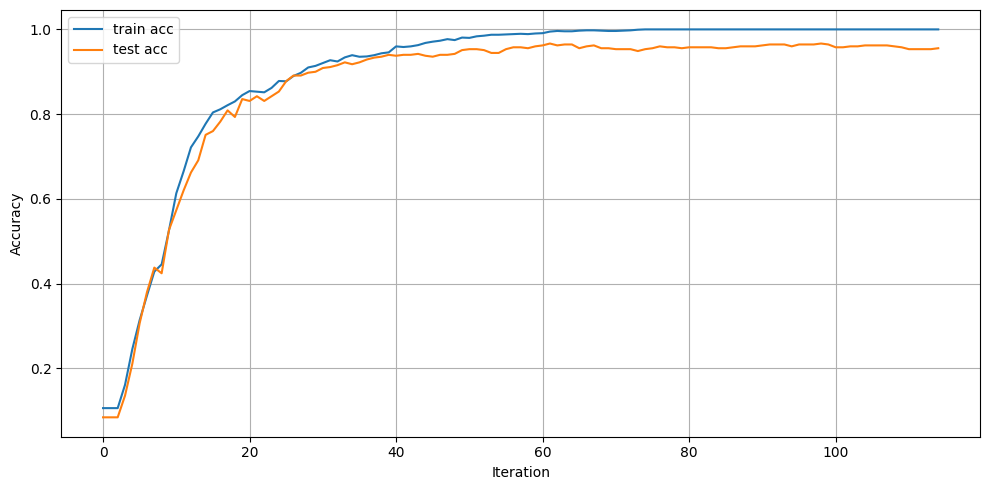

In [189]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(cb.train_acc, label="train acc")
ax.plot(cb.test_acc, label="test acc")
ax.set_xlabel("Iteration")
ax.set_ylabel("Accuracy")
ax.grid(True)
ax.legend()

fig.tight_layout()
plt.show()

### `Эксперименты с числом слоев (0.6 балла)`

Ясно, что из-за случайного начального приближения с каждым запуском обучения мы будем получать различное качество. Попробуем обучить нашу нейросеть с разным числом слоев несколько раз.

Заполните матрицы `accs_train` и `accs_test`. В позиции `[i, j]` должна стоять величина доли правильных ответов сети с $i+1$ полносвязными слоями при $j$-м запуске (все запуски идентичны).

In [198]:
accs_train = np.zeros((5, 5))
accs_test = np.zeros((5, 5))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

input_size = X_train.shape[1]
hidden_layers_size = 32
output_size = 10

for n_layer in range (1, 6):
    for j in range (5):
        network = make_network(input_size, hidden_layers_size, output_size, n_layer, ReLU)
        weights = get_weights(network)
        res = minimize(
            compute_loss_grad, weights,
            args=[network, X_train, y_train],
            method="L-BFGS-B",
            jac=True
        )

        set_weights(res.x, network)
        train_output = predict(network, X_train)
        test_output = predict(network, X_test)

        train_accuracy = np.mean(train_output == y_train)
        test_accuracy = np.mean(test_output == y_test)

        accs_train[n_layer-1][j] = train_accuracy
        accs_test[n_layer-1][j] = test_accuracy    

Построим боксплоты полученного качества (горизонтальная линия в каждом столбце — среднее, прямоугольник показывает разброс).

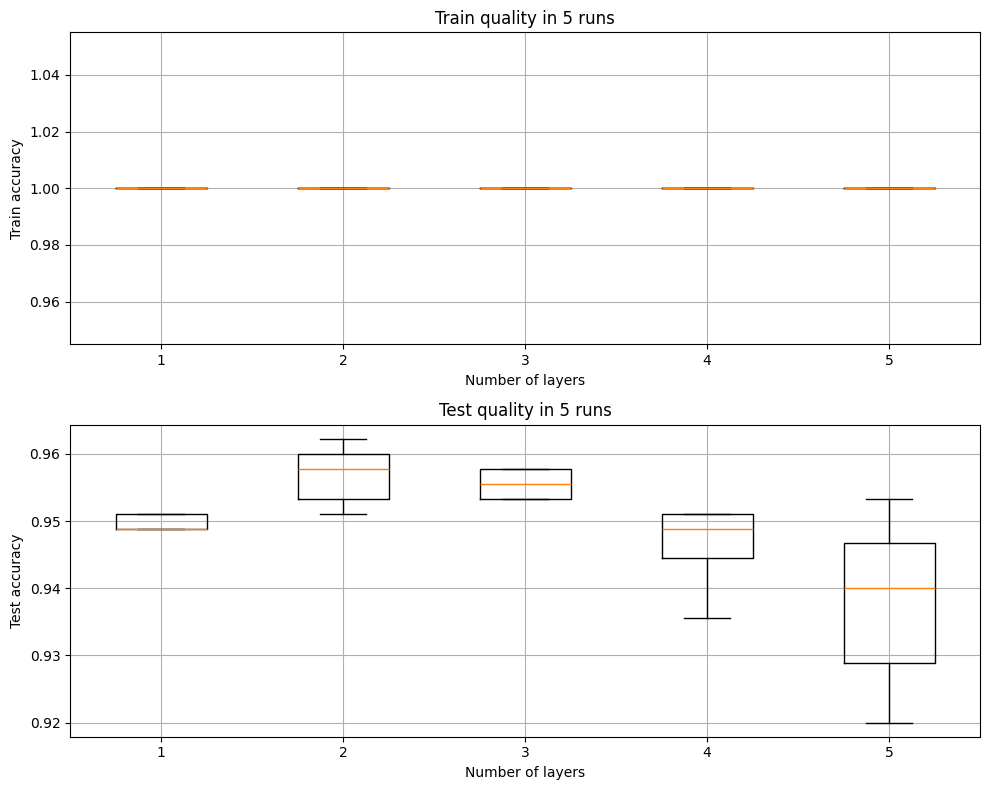

In [200]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].boxplot(accs_train.T, showfliers=False)
axes[1].boxplot(accs_test.T, showfliers=False)

axes[0].set_xlabel("Number of layers")
axes[1].set_xlabel("Number of layers")

axes[0].set_ylabel("Train accuracy")
axes[1].set_ylabel("Test accuracy")

axes[0].set_title("Train quality in 5 runs")
axes[1].set_title("Test quality in 5 runs")

axes[0].grid(True)
axes[1].grid(True)

fig.tight_layout()
plt.show()

Дайте развёрнутый ответ на вопросы (в этой же ячейке):
* Как изменяются качество на обучении и контроле и устойчивость процесса обучения при увеличении числа слоев?
* Можно ли сказать, что логистическая регрессия (линейная модель) дает качество хуже, чем нелинейная модель?

__Ответы:__

1. На тренировочной выборке качество стабильно высокое (100%) и стабильно устойчивое. А для тестовой выборки заметны следующие изменения: при увеличении числа слоев качество сначала растет, а затем снижается. Вероятно, это связано с переобучением: при большом количестве слоев нейросеть начинает запоминать, а не строить обобщения. При этом обучение становится более нестабильным, поэтому разброс accuracy увеличивается
2. Качество сильно зависит от параметров нейросети. Нелинейная модель хорошо работает на сложных задачах, но при это склонна к переобучению при неоптимальном подборе парамтеров (например, количестве слоев)

### `Эксперименты c различными инициализациями весов (0.6 балла)`

Как уже было сказано, начальная инициализация весов нейронной сети может сильно влиять на процесс ее обучения и, как следствие, на ее качество.

В этом пункте вам предлагается попробовать обучить несколько нейронных сетей с различными инициализациями слоев.

Для этого необходимо реализовать функцию, инициализирующую веса линейных слоёв нашей нейронной сети. Добавьте в функционал данного метода возможность инициализировать его веса с помощью инициализации Kaiming (используется, если в нейронной сети в качестве функций активации используется ReLU) и инициализации Xavier (используется, если в нейронной сети в качестве функций активации используется Tanh или Sigmoid):

In [32]:
def initialize_network(network, initialization):
    for layer in network:
        if isinstance(layer, Dense):
            input_units, output_units = layer.weights.shape
            if initialization == 'Kaiming':
                sqrt_var = np.sqrt(2 / input_units)
                layer.weights = np.random.randn(input_units, output_units) * sqrt_var
                pass
            elif initialization == 'Xavier':
                sqrt_var = np.sqrt(2 / (input_units + output_units))
                layer.weights = np.random.randn(input_units, output_units) * sqrt_var
                pass
            else:
                # Initialize weights with small random numbers from normal distribution.
                # In this case `initialization` represents a standard deviation
                # for normal distribution.
                layer.weights = np.random.randn(input_units, output_units) * initialization
            layer.biases = np.zeros_like(layer.biases)
            
            layer.params = [layer.weights, layer.biases]

Теперь попробуйте для каждой из 3 инициализаций обучить нейронную сеть несколько раз. Попробуйте проделать данную операцию при зафиксированном числе слоев равным 3, 4 и 5.

#### `3 слоя`

Зафиксируйте в сети число слоев равное трем.

Заполните матрицы `accs_train` и `accs_test`. В позиции `[i, j]` должна стоять величина доли правильных ответов сети при $j$-м запуске (все запуски идентичны) с инициализацией Kaiming при $i = 3$, с инициализацией Xavier при $i = 4$ и с инициализацией из нормального распределения с фиксированными параметрами при $0 \leqslant i \leqslant 2$ (попробуйте здесь 3 разных параметра для стандартного отклонения для нормального распределения, например: `1e-3`, `1e-2`, `1e-1`). Заметьте, что при большом числе слоев слишком низкое стандартное отклонение может не давать нейронной сети нормально обучиться.

In [215]:
init_vars = [1e-3, 1e-2, 1e-1, 'Kaiming', 'Xavier']

In [216]:
accs_train = np.zeros((5, 5))
accs_test = np.zeros((5, 5))

In [217]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

input_size = X_train.shape[1]
hidden_layers_size = 32
output_size = 10

for i, init_type in enumerate(init_vars):
    for j in range (5):
        network = make_network(input_size, hidden_layers_size, output_size, 3, ReLU)
        initialize_network(network, init_type)
        weights = get_weights(network)
        res = minimize(
            compute_loss_grad, weights,
            args=[network, X_train, y_train],
            method="L-BFGS-B",
            jac=True
        )

        set_weights(res.x, network)
        train_output = predict(network, X_train)
        test_output = predict(network, X_test)

        train_accuracy = np.mean(train_output == y_train)
        test_accuracy = np.mean(test_output == y_test)

        accs_train[i][j] = train_accuracy
        accs_test[i][j] = test_accuracy   

Построим боксплоты полученного качества (горизонтальная линия в каждом столбце — среднее, прямоугольник показывает разброс).

C:\Users\Пользователь\AppData\Local\Temp\ipykernel_6176\3438649196.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(accs_train.T, labels=init_vars_for_plot, showfliers=False)
C:\Users\Пользователь\AppData\Local\Temp\ipykernel_6176\3438649196.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(accs_test.T, labels=init_vars_for_plot, showfliers=False)


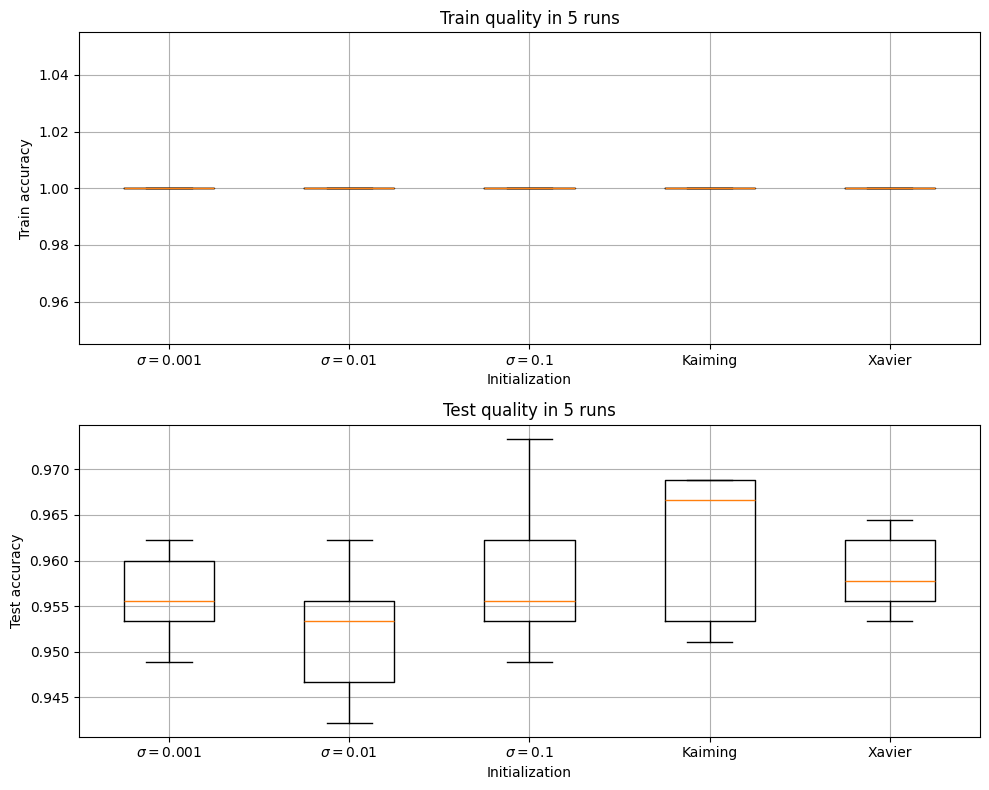

In [218]:
init_vars_for_plot = [(x if isinstance(x, str) else fr"$\sigma = {x}$") for x in init_vars]

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].boxplot(accs_train.T, labels=init_vars_for_plot, showfliers=False)
axes[1].boxplot(accs_test.T, labels=init_vars_for_plot, showfliers=False)

axes[0].set_xlabel("Initialization")
axes[1].set_xlabel("Initialization")

axes[0].set_ylabel("Train accuracy")
axes[1].set_ylabel("Test accuracy")

axes[0].set_title("Train quality in 5 runs")
axes[1].set_title("Test quality in 5 runs")

axes[0].grid(True)
axes[1].grid(True)

fig.tight_layout()
plt.show()

#### `4 слоя`

Выполните тут тот же код, что и в предыдущем пункте, но только уже с 4 слоями в сети.

In [219]:
init_vars = [5e-3, 1e-2, 1e-1, 'Kaiming', 'Xavier']

In [220]:
accs_train = np.zeros((5, 5))
accs_test = np.zeros((5, 5))

In [221]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

input_size = X_train.shape[1]
hidden_layers_size = 32
output_size = 10

for i, init_type in enumerate(init_vars):
    for j in range (5):
        network = make_network(input_size, hidden_layers_size, output_size, 4, ReLU)
        initialize_network(network, init_type)
        weights = get_weights(network)
        res = minimize(
            compute_loss_grad, weights,
            args=[network, X_train, y_train],
            method="L-BFGS-B",
            jac=True
        )

        set_weights(res.x, network)
        train_output = predict(network, X_train)
        test_output = predict(network, X_test)

        train_accuracy = np.mean(train_output == y_train)
        test_accuracy = np.mean(test_output == y_test)

        accs_train[i][j] = train_accuracy
        accs_test[i][j] = test_accuracy   

Построим боксплоты полученного качества (горизонтальная линия в каждом столбце — среднее, прямоугольник показывает разброс).

C:\Users\Пользователь\AppData\Local\Temp\ipykernel_6176\3438649196.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(accs_train.T, labels=init_vars_for_plot, showfliers=False)
C:\Users\Пользователь\AppData\Local\Temp\ipykernel_6176\3438649196.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(accs_test.T, labels=init_vars_for_plot, showfliers=False)


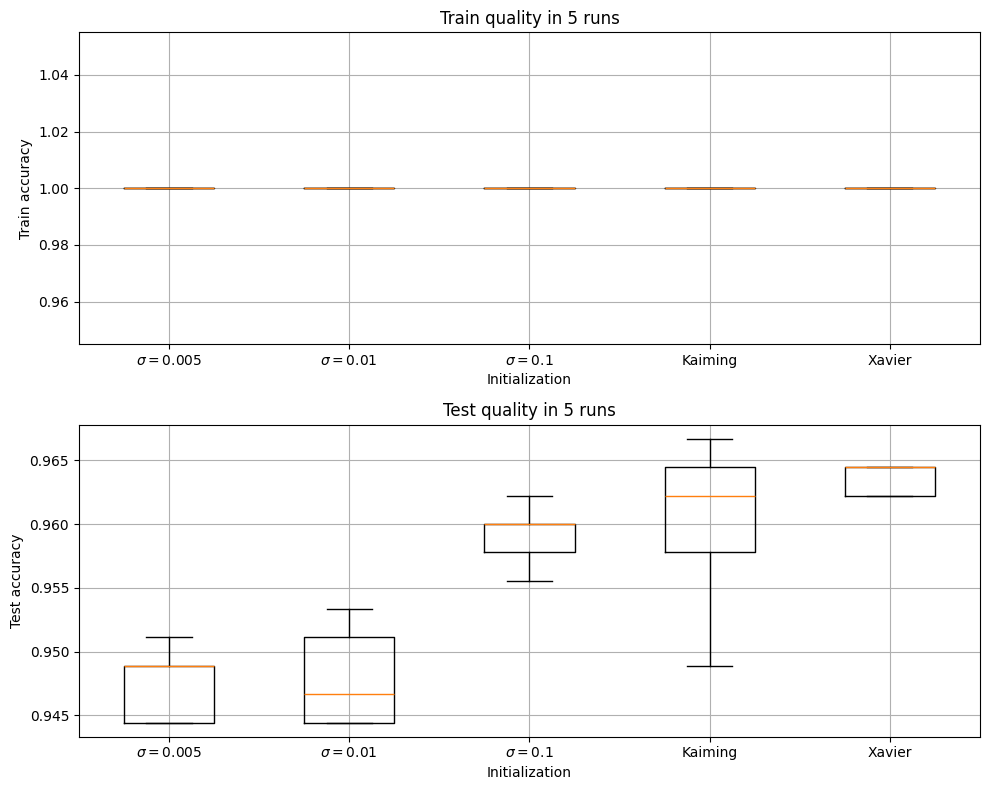

In [222]:
init_vars_for_plot = [(x if isinstance(x, str) else fr"$\sigma = {x}$") for x in init_vars]

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].boxplot(accs_train.T, labels=init_vars_for_plot, showfliers=False)
axes[1].boxplot(accs_test.T, labels=init_vars_for_plot, showfliers=False)

axes[0].set_xlabel("Initialization")
axes[1].set_xlabel("Initialization")

axes[0].set_ylabel("Train accuracy")
axes[1].set_ylabel("Test accuracy")

axes[0].set_title("Train quality in 5 runs")
axes[1].set_title("Test quality in 5 runs")

axes[0].grid(True)
axes[1].grid(True)

fig.tight_layout()
plt.show()

#### `5 слоев`

Выполните тут тот же код, что и в предыдущем пункте, но только уже с 5 слоями в сети.

In [223]:
init_vars = [1e-2, 1e-1, 1e0, 'Kaiming', 'Xavier']

In [224]:
accs_train = np.zeros((5, 5))
accs_test = np.zeros((5, 5))

In [225]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

input_size = X_train.shape[1]
hidden_layers_size = 32
output_size = 10

for i, init_type in enumerate(init_vars):
    for j in range (5):
        network = make_network(input_size, hidden_layers_size, output_size, 5, ReLU)
        initialize_network(network, init_type)
        weights = get_weights(network)
        res = minimize(
            compute_loss_grad, weights,
            args=[network, X_train, y_train],
            method="L-BFGS-B",
            jac=True
        )

        set_weights(res.x, network)
        train_output = predict(network, X_train)
        test_output = predict(network, X_test)

        train_accuracy = np.mean(train_output == y_train)
        test_accuracy = np.mean(test_output == y_test)

        accs_train[i][j] = train_accuracy
        accs_test[i][j] = test_accuracy   

Построим боксплоты полученного качества (горизонтальная линия в каждом столбце — среднее, прямоугольник показывает разброс).

C:\Users\Пользователь\AppData\Local\Temp\ipykernel_6176\3438649196.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(accs_train.T, labels=init_vars_for_plot, showfliers=False)
C:\Users\Пользователь\AppData\Local\Temp\ipykernel_6176\3438649196.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(accs_test.T, labels=init_vars_for_plot, showfliers=False)


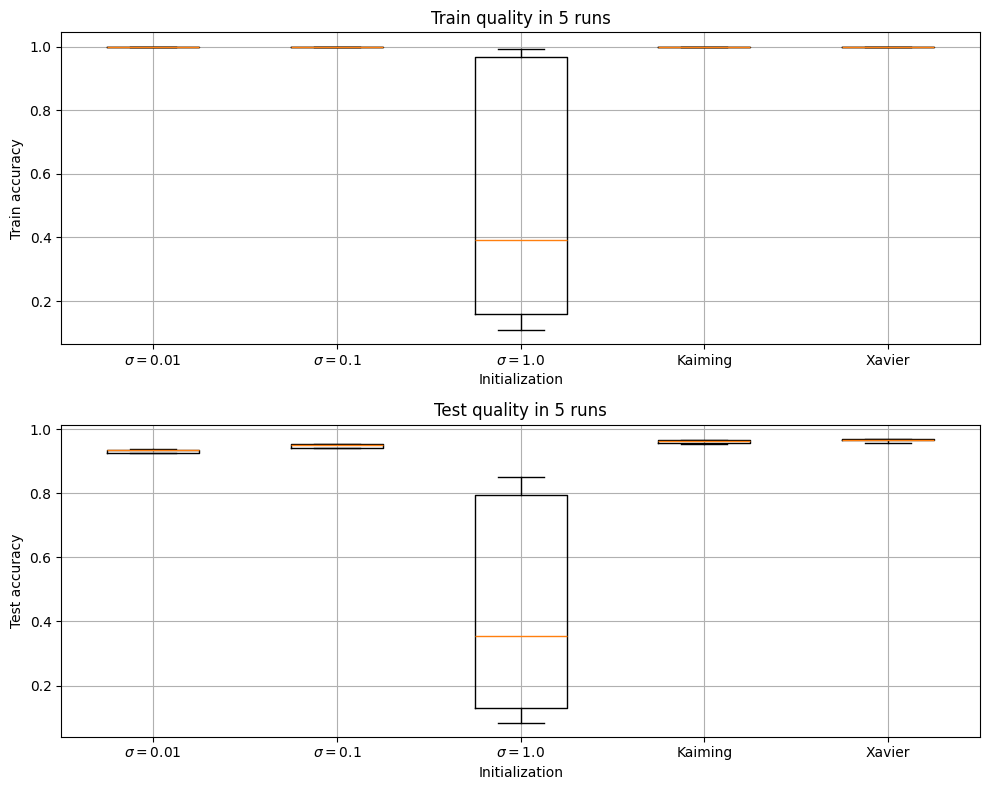

In [226]:
init_vars_for_plot = [(x if isinstance(x, str) else fr"$\sigma = {x}$") for x in init_vars]

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].boxplot(accs_train.T, labels=init_vars_for_plot, showfliers=False)
axes[1].boxplot(accs_test.T, labels=init_vars_for_plot, showfliers=False)

axes[0].set_xlabel("Initialization")
axes[1].set_xlabel("Initialization")

axes[0].set_ylabel("Train accuracy")
axes[1].set_ylabel("Test accuracy")

axes[0].set_title("Train quality in 5 runs")
axes[1].set_title("Test quality in 5 runs")

axes[0].grid(True)
axes[1].grid(True)

fig.tight_layout()
plt.show()

Дайте развёрнутый ответ на вопросы (в этой же ячейке):
* Как отличаются качество на обучении и контроле и устойчивость процесса обучения при различных инициализациях?
* Какие инициализации помогают обучать более глубокие сети?

__Ответы:__

1. а) *3 слоя.* Видно, что наибольшее качество обучение у Kaiming, что логично, так как она наиболее оптимальна при функции активации ReLU, которую мы используем. У Xavier качество хоть и ниже Kaiming, но все еще выше рандомной инициализации. При это дисперсия влияет на качество обучения нелинейно. При этом, наибольшая неуйстойчивость наблюдается у Kaiming.

    б) *4 слоя.* При увеличении дисперсии точность обучения растет. При этом у Xavier качество и устойчивость выше, чем у Kaiming.

    в) *5 слоев.* При таком количестве слоев в среднем качество и устойчивость обучения высокие, так как, скорее всего, количество слоев влияет сильно больше, чем тип инициалиации весов. Однако при наибольшей дисперсии наблюдается понижения качества и устойчивости обучения.Видимо,слишком большая дисперсия весов приводит к сильному росту активаций на прямом проходе и градиентов на обратном, что приводит к низкой точности и неустойчивости.

2. Kaiming и Xavier хорошо себя работают на глубоких сетях, хотя это не единственный вариант.

Теперь сравним скорость обучения при различных инициализациях. Создайте два списка списков `accs_test_on_iterations`, `accs_train_on_iterations` в каждом из которых в позиции `[i]` (см. описание `i` в предыдущем пункте) будет лежать список из значений `accuracy` на тестовой и обучающей выборках соотвественно, полученных во время обучения модели. Количество слоев в сети зафиксируйте равным 4.

In [237]:
init_vars = [1e-3, 1e-2, 1e-1, 'Kaiming', 'Xavier']

In [238]:
accs_test_on_iterations = []
accs_train_on_iterations = []

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

input_size = X_train.shape[1]
hidden_layers_size = 32
output_size = 10

for init_type in init_vars:
    network = make_network(input_size, hidden_layers_size, output_size, 4, ReLU)
    initialize_network(network, init_type)
    weights = get_weights(network)

    cb = Callback(network, X_train, y_train, X_test, y_test, print=True)

    res = minimize(
        compute_loss_grad, weights,  
        args=[network, X_train, y_train], 
        method="L-BFGS-B",
        jac=True,
        callback=cb.call
    )

    set_weights(res.x, network)
    train_output = predict(network, X_train)
    test_output = predict(network, X_test)

    accs_train_on_iterations.append(cb.train_acc)
    accs_test_on_iterations.append(cb.test_acc)

0.10616184112843356 0.08444444444444445
0.10616184112843356 0.08444444444444445
0.10616184112843356 0.08444444444444445
0.10616184112843356 0.08444444444444445
0.10616184112843356 0.08444444444444445
0.16184112843355605 0.1511111111111111
0.10319227913882702 0.09555555555555556
0.10319227913882702 0.09555555555555556
0.10467706013363029 0.09333333333333334
0.13882702301410543 0.14
0.15961395694135114 0.1622222222222222
0.24870081662954716 0.2288888888888889
0.3028953229398664 0.28444444444444444
0.2835931700074239 0.26666666666666666
0.3593170007423905 0.34
0.40979955456570155 0.39111111111111113
0.48329621380846327 0.4577777777777778
0.5270972531551597 0.4822222222222222
0.6028210838901262 0.5911111111111111
0.6117297698589458 0.5911111111111111
0.6317743132887899 0.6066666666666667
0.6555308092056422 0.6466666666666666
0.6792873051224945 0.64
0.6926503340757239 0.6511111111111111
0.7023014105419451 0.6533333333333333
0.7282850779510023 0.6622222222222223
0.7312546399406088 0.66666666

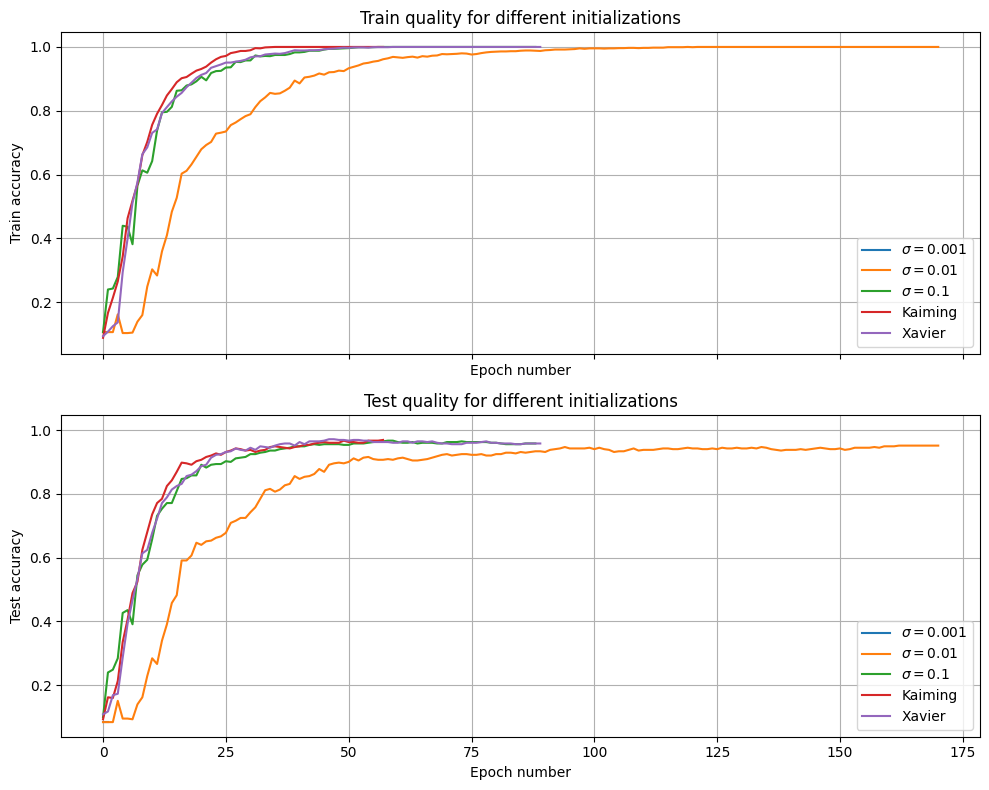

In [240]:
init_vars_for_plot = [(x if isinstance(x, str) else fr"$\sigma = {x}$") for x in init_vars]

fig, ax = plt.subplots(2, 1, sharex=True, sharey=True,  figsize=(10, 8))

for idx, label in enumerate(init_vars_for_plot):
    ax[0].plot(accs_train_on_iterations[idx], label=label)
    ax[1].plot(accs_test_on_iterations[idx], label=label)

for idx, key in enumerate(["Train", "Test"]):
    ax[idx].set_title(f"{key} quality for different initializations")
    ax[idx].set_xlabel("Epoch number")
    ax[idx].set_ylabel(f"{key} accuracy")
    ax[idx].grid(True)
    ax[idx].legend()



fig.tight_layout()
plt.show()

Дайте развёрнутый ответ на вопросы (в этой же ячейке):
* Как меняется скорость cходимости в зависимости от выбранной инициализации?

__Ответы:__

При именных инициализациях скорость сходимости наибольшая, особенно при Kaiming, так как она обычно используется при функции активации ReLU. При уменьшении дисперсии скорость сходимости уменьшается. При этом видим, что при самой маленькой дисперсии обучение не происходит. Возможно веса слишком маленькие и обучение сразу же останавливается.

### `Эксперименты c различными функциями активации (0.6 балла)`

Проверим теперь, с какой функцией активации нейронная сеть будет обучаться лучше.

В этом пункте вам предлагается попробовать обучить несколько нейронных сетей с различными функциями активации.

Для этого нам нужно реализовать еще 2 слоя: для функций активации `Tanh` и `Sigmoid`.

In [29]:
class Tanh:
    """
    tanh(y) = (e^y - e^(-y)) / (e^y + e^(-y))
    Используйте функцию np.tanh для подсчета гиперболического тангенса.
    Вы можете сами реализовать подсчет tanh, но тогда вам нужно устойчиво его вычислять.
    """
    def __init__(self):
        self.params = [] # Tanh has no parameters

    def forward(self, input):
        """
        Apply elementwise Tanh to [batch, num_units] matrix
        """
        tanh_y = np.tanh(input)
        self.mask = tanh_y
        return tanh_y

    def backward(self, grad_output):
        """
        Compute gradient of loss w.r.t. Tanh input
        grad_output shape: [batch, num_units]
        output 1 shape: [batch, num_units]
        output 2: []
        """
        grad_input = (1 - self.mask**2) * grad_output
        return grad_input, []
        

    def __repr__(self):
        return 'Tanh()'

In [30]:
from scipy.special import expit
    
class Sigmoid:
    """
    sigmoid(y) = 1 / (1 + e^(-y))
    Используйте функцию expit для подсчета сигмоиды.
    Вы можете сами реализовать подсчет сигмоиды, но тогда вам нужно устойчиво ее вычислять.
    """
    def __init__(self):
        self.params = [] # Sigmoid has no parameters

    def forward(self, input):
        """
        Apply elementwise Sigmoid to [batch, num_units] matrix
        """
        output = expit(input)
        self.mask = output
        return output

    def backward(self, grad_output):
        """
        Compute gradient of loss w.r.t. Sigmoid input
        grad_output shape: [batch, num_units]
        output 1 shape: [batch, num_units]
        output 2: []
        """
        grad_input = self.mask*(1 - self.mask)*grad_output
        return grad_input, []

    def __repr__(self):
        return 'Sigmoid()'

Теперь попробуйте для каждой из 3 функций активации обучить нейронную сеть несколько раз. Число слоев зафиксируйте равным 3. В случае `Tanh` и `Sigmoid` используйте инициализацию `Xavier`, а в случае `ReLU` используйте инициализацию `Kaiming`.

Заполните матрицы `accs_train` и `accs_test`. В позиции `[i, j]` должна стоять величина доли правильных ответов сети при $j$-м запуске (все запуски идентичны) с функцией активации $ReLU$ при $i = 0$, с функцией активации $Tanh$ при $i = 1$ и с функцией активации $Sigmoid$ при $i = 2$.

In [272]:
act_func_vars = ['Tanh', 'Sigmoid', 'ReLU']
init_for_act_funcs = ['Xavier', 'Xavier', 'Kaiming']

In [273]:
accs_train = np.zeros((3, 5))
accs_test = np.zeros((3, 5))

In [274]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

input_size = X_train.shape[1]
hidden_layers_size = 32
output_size = 10

order = [2, 0, 1]

activation_map = {
    'ReLU': ReLU,
    'Tanh': Tanh,
    'Sigmoid': Sigmoid
}

for i in range(3):
    act_class = activation_map[act_func_vars[order[i]]]
    init_type = init_for_act_funcs[order[i]]
    for j in range (5):
        network = make_network(input_size, hidden_layers_size, output_size, 3, act_class)
        initialize_network(network, init_type)
        weights = get_weights(network)
        res = minimize(
            compute_loss_grad, weights,
            args=[network, X_train, y_train],
            method="L-BFGS-B",
            jac=True
        )

        set_weights(res.x, network)
        train_output = predict(network, X_train)
        test_output = predict(network, X_test)

        train_accuracy = np.mean(train_output == y_train)
        test_accuracy = np.mean(test_output == y_test)

        accs_train[i][j] = train_accuracy
        accs_test[i][j] = test_accuracy   

Построим боксплоты полученного качества (горизонтальная линия в каждом столбце — среднее, прямоугольник показывает разброс).

C:\Users\Пользователь\AppData\Local\Temp\ipykernel_6176\3288514040.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0].boxplot(accs_train[order].T, labels=act_func_vars, showfliers=False)
C:\Users\Пользователь\AppData\Local\Temp\ipykernel_6176\3288514040.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[1].boxplot(accs_test[order].T, labels=act_func_vars, showfliers=False)


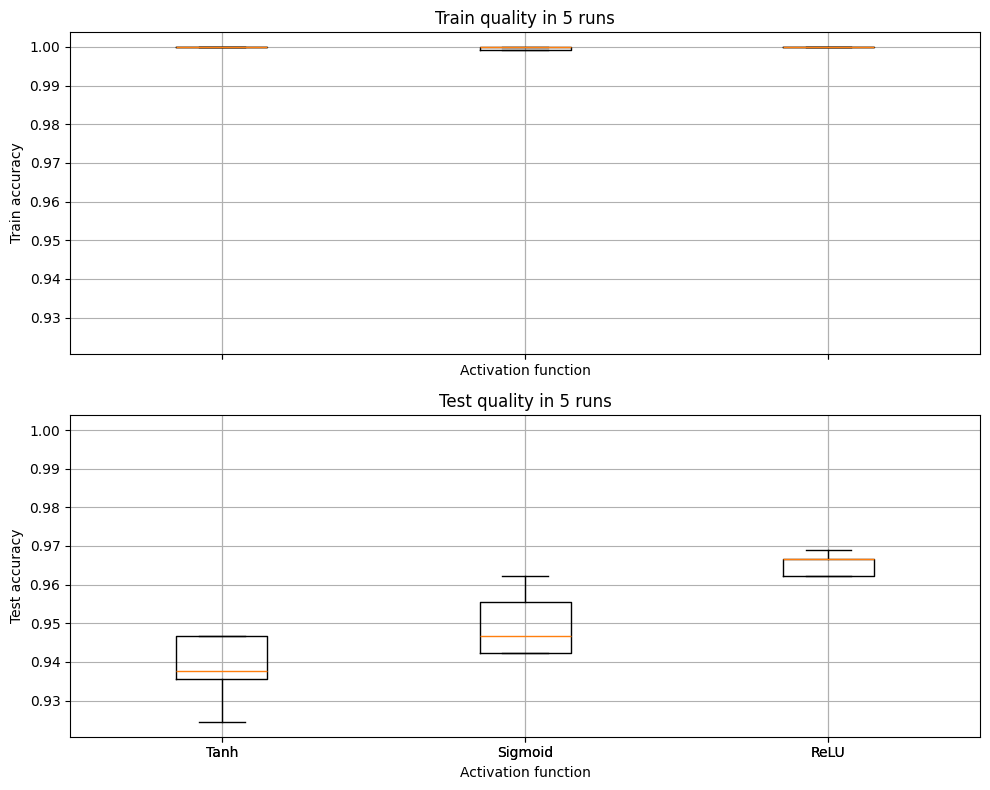

In [276]:
fig, ax = plt.subplots(2, 1, sharex=True, sharey=True,  figsize=(10, 8))

order = [1, 2, 0]

ax[0].boxplot(accs_train[order].T, labels=act_func_vars, showfliers=False)
ax[1].boxplot(accs_test[order].T, labels=act_func_vars, showfliers=False)

ax[0].set_title("Train quality in 5 runs")
ax[1].set_title("Test quality in 5 runs")

ax[0].set_xlabel("Activation function")
ax[1].set_xlabel("Activation function")

ax[0].set_ylabel("Train accuracy")
ax[1].set_ylabel("Test accuracy")

ax[0].grid(True)
ax[1].grid(True)

fig.tight_layout()
plt.show()

Дайте развёрнутый ответ на вопросы (в этой же ячейке):
* Как отличаются качество на обучении и контроле и устойчивость процесса обучения при различных функциях активации?

__Ответы:__

ReLU дает наиболее качественное и устойчивое обучени. Наибольшую неустойчивость демонстрирует сигмоида, при этом меньшее качество обучения у Tanh

\* Несколько фрагментов кода в задании написаны на основе материалов [курса по глубинному обучению на ФКН НИУ ВШЭ](https://www.hse.ru/ba/ami/courses/205504078.html)

### `Реализация метода оптимизации (1.4 балла)`

В этой части задания реализуйте метод оптимизации SGD + momentum. Упрощённая версия более общего алгоритма [отсюда](https://pytorch.org/docs/stable/generated/torch.optim.SGD.html):

$$
\begin{aligned}
    &\rule{70mm}{0.4pt}                                                             \\
    &\textbf{input}      : \gamma \text{ (lr)}, \: \theta_0 \text{ (params)}, \: X \text{ (data)},       \\
    &\hspace{13mm} \: f(\theta) \text{ (objective)}, \:\mu \text{ (momentum)}       \\[-1.ex]
    &\rule{70mm}{0.4pt}                                                             \\
    &\textbf{for} \: t=1 \: \textbf{to} \: \ldots \: \textbf{do}                    \\
    &\hspace{5mm}\mathcal{X} \leftarrow \texttt{list\_of\_random\_batches}(X)\\
    &\hspace{5mm}\textbf{for} \: i=1 \: \textbf{to} \: \ldots \: \textbf{do}                    \\
    &\hspace{10mm}g_t\leftarrow   \nabla_{\theta} f_t (\theta_{t-1},\mathcal{X}_i)      \\
    &\hspace{10mm}\textbf{if} \: \mu \neq 0                                          \\
    &\hspace{15mm}\textbf{if} \: t > 1                                              \\
    &\hspace{20mm} \textbf{b}_t \leftarrow \mu \textbf{b}_{t-1} + g_t               \\
    &\hspace{15mm}\textbf{else}                                                     \\
    &\hspace{20mm} \textbf{b}_t \leftarrow g_t                                      \\
    &\hspace{15mm} g_t  \leftarrow  \textbf{b}_t                                     \\
    &\hspace{10mm}\theta_t \leftarrow \theta_{t-1} - \gamma g_t                      \\[-1.ex]
    &\rule{70mm}{0.4pt}                                                             \\[-1.ex]
    &\bf{return} \:  \theta_t                                                       \\[-1.ex]
    &\rule{70mm}{0.4pt}                                                             \\[-1.ex]
\end{aligned}
$$

Проще всего будет написать `custom minimizer` (смотри [документацию scipy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html)).

In [1]:
from scipy.optimize import OptimizeResult


def SGD(fun, x0, args, **kwargs) -> OptimizeResult:
    callback = kwargs['callback']   # feed weights from each iteration to update network and log metrics
    mu = kwargs['momentum']
    n_iter = kwargs['n_iter']
    gamma = kwargs['lr']
    jac = kwargs['jac']
    batch_size = kwargs['batch_size']
    
    net, X, y = args
    theta = x0.copy()
    v = np.zeros_like(theta)
    steps = 0

    for epoch in range(n_iter):
        indices = np.random.permutation(len(X))
        start = 0
        N = len(indices)
        while start < N:
            end = min(start + batch_size, N)
            batch_idx = indices[start:end]
            X_batch = X[batch_idx]
            y_batch = y[batch_idx]

            grad = fun(theta, (net, X_batch, y_batch))[1]

            if mu != 0:
                if steps == 0:
                    v = grad
                else:
                    v = mu*v + grad
            else:
                v = grad

            theta -= gamma*v
            if callback is not None:
                callback(theta)
            start += batch_size
            steps += 1
        
    final_loss = fun(theta, (net, X, y))[0]

    output = OptimizeResult()
    output.x = theta
    output.fun = final_loss
    output.nit = steps
    output.success = True

    return output

**Задание 1. (0.5 балла)** Продемонстрируйте правильную работу метода оптимизации, получив `test_accuracy>=0.9`.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

input_size = X_train.shape[1]
hidden_layers_size = 32
output_size = 10

network = make_network(input_size, hidden_layers_size, output_size, 4, ReLU)

mu = 0.9
n_iter = 40
gamma = 0.01
batch_size = 32

initialize_network(network, 'Kaiming')
weights = get_weights(network)

res = SGD(
    fun = compute_loss_grad,
    x0=weights,
    args = (network, X_train, y_train),
    momentum = mu,
    n_iter = n_iter,
    lr = gamma,
    jac=True,
    batch_size = batch_size,
    callback = None  
)

set_weights(res.x, network)
train_output = predict(network, X_train)
test_output = predict(network, X_test)

train_accuracy = np.mean(train_output == y_train)
test_accuracy = np.mean(test_output == y_test)

print(f"Test accuracy: {test_accuracy:.4f}")  

Test accuracy: 0.9578


**Задание 2. (0.8 балла)** Сравните три алгоритма:
1. LBFGS-B
2. SGD
3. SGD + momentum

Для этого одновременно переберите следующие гиперпараметры:
- значения `lr` на отрезке `[1e-3, 1e-1]` по логарифмической сетке
- два значения `momentum`: `0` и `0.9`
- значения `batch_size`: `8` и `32`

В каждом запуске сохраняйте три метрики: итоговое accuracy на тесте и на трейне и время обучения.

Для каждого из трёх алгоритмов выберите лучшие `lr` и `batch_size` по `test_accuracy`. Постройте для них кривые обучения (пример ниже). Сделайте выводы.

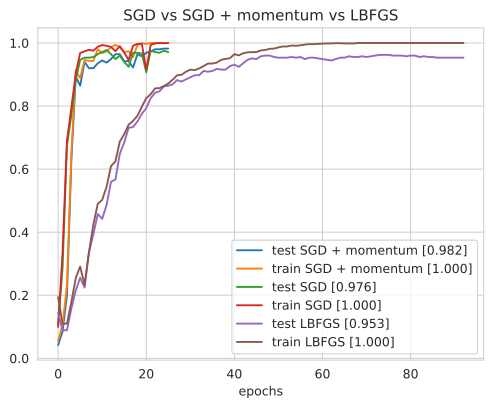

In [49]:
import time
import itertools

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

input_size = X_train.shape[1]
hidden_size = 32
output_size = 10
n_iter = 40

lr_values = np.logspace(-3, -1, num=5)
batch_sizes = [8, 32]
momentum_values = [0, 0.9]

accs_train_on_methods = []
accs_test_on_methods = []

results = {
    'L-BFGS-B': {'test_acc': None, 'train_acc': None, 'time': None, 'history': None},
    'SGD_mom0': {'combinations': [], 'test_acc': [], 'train_acc': [], 'time': [], 'histories': []},
    'SGD_mom09': {'combinations': [], 'test_acc': [], 'train_acc': [], 'time': [], 'histories': []}
}

network = make_network(input_size, hidden_size, output_size, 4, ReLU)
initialize_network(network, 'Kaiming')

cb = Callback(network, X_train, y_train, X_test, y_test, print=False)
weights = get_weights(network)
start = time.time()

res = minimize(
    compute_loss_grad, weights, 
    args=[network, X_train, y_train],
    method='L-BFGS-B', 
    jac=True,
    callback=cb.call
)

end = time.time() - start
set_weights(res.x, network)
train_acc = np.mean(predict(network, X_train) == y_train)
test_acc = np.mean(predict(network, X_test) == y_test)

results['L-BFGS-B']['train_acc'] = train_acc
results['L-BFGS-B']['test_acc'] = test_acc
results['L-BFGS-B']['time'] = end
results['L-BFGS-B']['history'] = (cb.train_acc, cb.test_acc)

print(f"L-BFGS-B: test_acc = {test_acc:.4f}, time = {end:.2f}s")

best_histories = {'SGD_mom0': None, 'SGD_mom09': None}

for mu in momentum_values:
    algo_key = 'SGD_mom0' if mu == 0 else 'SGD_mom09'
    best_test = -1
    best_history = None

    for lr, batch_size in itertools.product(lr_values, batch_sizes):
        network = make_network(input_size, hidden_size, output_size, 4, ReLU)
        initialize_network(network, 'Kaiming')
        weights = get_weights(network)
        cb = Callback(network, X_train, y_train, X_test, y_test, print=False)

        start = time.time()
        res = SGD(
            fun=compute_loss_grad,
            x0=weights,
            args=(network, X_train, y_train),
            momentum=mu,
            n_iter=n_iter,
            lr=lr,
            jac=True,
            batch_size=batch_size,
            callback=cb.call
        )
        end = time.time() - start
        set_weights(res.x, network)
        train_acc = np.mean(predict(network, X_train) == y_train)
        test_acc = np.mean(predict(network, X_test) == y_test)

        results[algo_key]['combinations'].append((lr, batch_size))
        results[algo_key]['train_acc'].append(train_acc)
        results[algo_key]['test_acc'].append(test_acc)
        results[algo_key]['time'].append(end)
        results[algo_key]['histories'].append((cb.train_acc.copy(), cb.test_acc.copy()))

        if test_acc > best_test:
            best_test = test_acc
            best_history = (cb.train_acc.copy(), cb.test_acc.copy())
            best_params = (lr, batch_size)

        print(f"  lr={lr:.4f}, batch={batch_size:2d}: test_acc={test_acc:.4f}, time={end:.2f}s")

    results[algo_key]['best_history'] = best_history
    results[algo_key]['best_params'] = best_params
    results[algo_key]['best_test'] = best_test
    print(f"Best for {algo_key}: lr={best_params[0]:.4f}, batch={best_params[1]}, test_acc={best_test:.4f}")

print(f"L-BFGS-B: test_acc = {results['L-BFGS-B']['test_acc']:.4f}")

for algo in ['SGD_mom0', 'SGD_mom09']:
    idx = np.argmax(results[algo]['test_acc'])
    best_lr, best_batch = results[algo]['combinations'][idx]
    print(f"{algo}: best test_acc = {results[algo]['test_acc'][idx]:.4f} "
          f"with lr={best_lr:.4f}, batch_size={best_batch}")

L-BFGS-B: test_acc = 0.9622, time = 0.76s
  lr=0.0010, batch= 8: test_acc=0.9267, time=69.22s
  lr=0.0010, batch=32: test_acc=0.8978, time=19.59s
  lr=0.0032, batch= 8: test_acc=0.9600, time=61.31s
  lr=0.0032, batch=32: test_acc=0.9267, time=8.50s
  lr=0.0100, batch= 8: test_acc=0.9578, time=54.97s
  lr=0.0100, batch=32: test_acc=0.9622, time=19.88s
  lr=0.0316, batch= 8: test_acc=0.9178, time=75.90s
  lr=0.0316, batch=32: test_acc=0.9622, time=19.97s
  lr=0.1000, batch= 8: test_acc=0.0978, time=72.10s
  lr=0.1000, batch=32: test_acc=0.0844, time=18.40s
Best for SGD_mom0: lr=0.0100, batch=32, test_acc=0.9622
  lr=0.0010, batch= 8: test_acc=0.9600, time=58.24s
  lr=0.0010, batch=32: test_acc=0.9489, time=16.92s
  lr=0.0032, batch= 8: test_acc=0.9756, time=82.94s
  lr=0.0032, batch=32: test_acc=0.9578, time=12.25s
  lr=0.0100, batch= 8: test_acc=0.1000, time=39.89s
  lr=0.0100, batch=32: test_acc=0.9289, time=18.68s
  lr=0.0316, batch= 8: test_acc=0.0844, time=65.39s
  lr=0.0316, batch=

Построим графики

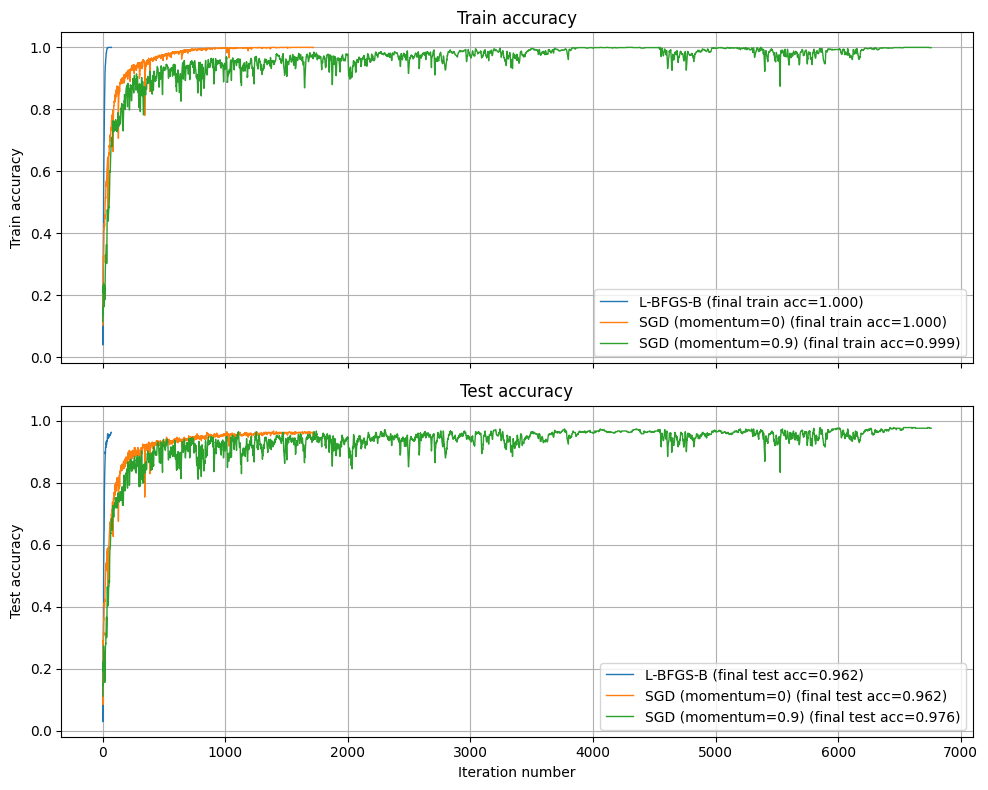

In [53]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, sharey=True, figsize=(10, 8))

train_hist, test_hist = results['L-BFGS-B']['history']
ax1.plot(train_hist, linewidth=1, label=f"L-BFGS-B (final train acc={train_hist[-1]:.3f})")
ax2.plot(test_hist, linewidth=1, label=f"L-BFGS-B (final test acc={test_hist[-1]:.3f})")

for algo_key in ['SGD_mom0', 'SGD_mom09']:
    label_base = 'SGD (momentum=0)' if algo_key == 'SGD_mom0' else 'SGD (momentum=0.9)'
    train_hist, test_hist = results[algo_key]['best_history']
    ax1.plot(train_hist, linewidth=1, label=f"{label_base} (final train acc={train_hist[-1]:.3f})")
    ax2.plot(test_hist, linewidth=1, label=f"{label_base} (final test acc={test_hist[-1]:.3f})")

ax1.set_title('Train accuracy')
ax2.set_title('Test accuracy')
ax2.set_xlabel('Iteration number')
ax1.set_ylabel('Train accuracy')
ax2.set_ylabel('Test accuracy')
ax1.grid(True)
ax2.grid(True)
ax1.legend()
ax2.legend()
fig.tight_layout()
plt.show()

**Выводы:**

Видно, что быстрее всего завершается алгоритм 'L-BFGS-S', затем идет SGD и SGD+momentum. При этом качество обучения выше всего у SGD+momentum. Однако так же для этого метода видим сильный разброс в accuracy по итерациям, что вероятнее всего связано с размером оптимального батча (8). Маленький размер батча приводит к "выбросам" в течение обучения.

**Задание 3. (0.1 балла)** Для отобранных в прошлом задании трёх алгоритмов ответье на вопрос: как меняются запуски для двух значений `batch_size`.

**Ответ:**
При маленьких размеров батча время обучения сильно увеличивается, что звучит логично. Также при большем размере батча разброс результатов меньше, но качество обучения ниже. 

## `Бонусная часть`

### `Реализация метода оптимизации (1 балл)`

Реализуйте метод оптимизации Adam и сравните его работу с SGD + momentum, проведя эксперимент, как в задании 2 (перебор гиперпараметров + кривые обучения).

### `Dropout (1 балл)`

Реализуйте слой Dropout. Сравните обучение сети из большого числа слоёв при использовании Dropout и без его использования (предварительно подберите адекватный параметр $p$). Сделайте выводы.

### `BatchNormalization (1 балл)`

Реализуйте слой `BatchNormalization`. Сравните обучение сети из большого числа слоёв при использовании `BatchNormalization` и без его использования. Сделайте выводы.